In [80]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [81]:
delivery_data = pd.read_csv("../data/olist_delivery_time_data.csv")
delivery_data.head()

,order_id,purchase_dayofweek,purchase_month,purchase_hour,purchase_is_weekend,estimated_delivery_days,n_items,n_sellers,total_price,total_freight,...,product_width_cm,payment_installments,payment_value,payment_type,customer_state,seller_state,product_category_name_english,distance_km,same_state,delivery_time_days
0,e481f51cbdc54678b7cc49136f2d6af7,0,10,10,0,15.544063,1,1,29.99,8.72,...,13.0,1.0,38.71,voucher,SP,SP,housewares,18.681711,1,8.436574
1,53cdb2fc8bc7dce0b6741e2150273451,1,7,20,0,19.137766,1,1,118.70,22.76,...,19.0,1.0,141.46,boleto,BA,SP,perfumery,861.035367,0,13.782037
2,47770eb9100c2d0c44946d9cf07ec65d,2,8,8,0,26.639711,1,1,159.90,19.22,...,21.0,3.0,179.12,credit_card,GO,SP,auto,514.547140,0,9.394213
3,949d5b44dbf5de918fe9c16f97b45f8a,5,11,19,1,26.188819,1,1,45.00,27.20,...,20.0,1.0,72.20,credit_card,RN,MG,pet_shop,1821.802656,0,13.208750
4,ad21c59c0840e6cb83a9ceb5573f8159,1,2,21,0,12.112049,1,1,19.90,8.72,...,15.0,1.0,28.62,credit_card,SP,SP,stationery,29.593095,1,2.873877


## Understanding data

In [82]:
print(f"The data has {delivery_data.shape[0]} rows and {delivery_data.shape[1]} columns.")

The data has 96478 rows and 24 columns.


In [83]:
# Structural summary of data
delivery_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 96478 entries, 0 to 96477
Data columns (total 24 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   order_id                       96478 non-null  str    
 1   purchase_dayofweek             96478 non-null  int64  
 2   purchase_month                 96478 non-null  int64  
 3   purchase_hour                  96478 non-null  int64  
 4   purchase_is_weekend            96478 non-null  int64  
 5   estimated_delivery_days        96478 non-null  float64
 6   n_items                        96478 non-null  int64  
 7   n_sellers                      96478 non-null  int64  
 8   total_price                    96478 non-null  float64
 9   total_freight                  96478 non-null  float64
 10  avg_price                      96478 non-null  float64
 11  product_weight_g               96462 non-null  float64
 12  product_length_cm              96462 non-null  float64
 1

In [84]:
# Statistical summary of data
delivery_data.describe()

,purchase_dayofweek,purchase_month,purchase_hour,purchase_is_weekend,estimated_delivery_days,n_items,n_sellers,total_price,total_freight,avg_price,product_weight_g,product_length_cm,product_height_cm,product_width_cm,payment_installments,payment_value,distance_km,same_state,delivery_time_days
count,96478.000000,96478.000000,96478.000000,96478.000000,96478.000000,96478.000000,96478.000000,96478.000000,96478.000000,96478.000000,96462.000000,96462.000000,96462.000000,96462.000000,96477.000000,96477.000000,96000.000000,96478.000000,96470.000000
mean,2.756577,6.031116,14.773192,0.230001,23.736347,1.142198,1.013900,137.041586,22.785253,125.234076,2097.746968,30.093125,16.447803,23.013891,2.928024,159.856357,600.654736,0.359730,12.558217
std,1.967058,3.228391,5.328374,0.420835,8.760765,0.538804,0.123536,209.045198,21.559197,189.698083,3754.111279,16.097278,13.284786,11.723022,2.712723,218.813144,594.146033,0.479924,9.546156
min,0.000000,1.000000,0.000000,0.000000,2.008009,1.000000,1.000000,0.850000,0.000000,0.850000,0.000000,7.000000,2.000000,6.000000,0.000000,9.590000,0.000000,0.000000,0.533414
25%,1.000000,3.000000,11.000000,0.000000,18.330081,1.000000,1.000000,45.900000,13.850000,41.908333,300.000000,18.000000,8.000000,15.000000,1.000000,61.880000,184.972815,0.000000,6.766204
50%,3.000000,6.000000,15.000000,0.000000,23.230880,1.000000,1.000000,86.575000,17.170000,79.000000,700.000000,25.000000,13.000000,20.000000,2.000000,105.280000,433.773044,0.000000,10.217477
75%,4.000000,8.000000,19.000000,0.000000,28.407590,1.000000,1.000000,149.900000,24.017500,139.900000,1800.000000,38.000000,20.000000,30.000000,4.000000,176.330000,798.210166,1.000000,15.720182
max,6.000000,12.000000,23.000000,1.000000,155.135463,21.000000,5.000000,13440.000000,1794.960000,6735.000000,40425.000000,105.000000,105.000000,118.000000,24.000000,13664.080000,8677.859564,1.000000,209.628611


In [85]:
# Columns in data
print("Columns:", delivery_data.columns)

Columns: Index(['order_id', 'purchase_dayofweek', 'purchase_month', 'purchase_hour',
       'purchase_is_weekend', 'estimated_delivery_days', 'n_items',
       'n_sellers', 'total_price', 'total_freight', 'avg_price',
       'product_weight_g', 'product_length_cm', 'product_height_cm',
       'product_width_cm', 'payment_installments', 'payment_value',
       'payment_type', 'customer_state', 'seller_state',
       'product_category_name_english', 'distance_km', 'same_state',
       'delivery_time_days'],
      dtype='str')


In [86]:
# Datatypes in data
delivery_data.dtypes

order_id                             str
purchase_dayofweek                 int64
purchase_month                     int64
purchase_hour                      int64
purchase_is_weekend                int64
estimated_delivery_days          float64
n_items                            int64
n_sellers                          int64
total_price                      float64
total_freight                    float64
avg_price                        float64
product_weight_g                 float64
product_length_cm                float64
product_height_cm                float64
product_width_cm                 float64
payment_installments             float64
payment_value                    float64
payment_type                         str
customer_state                       str
seller_state                         str
product_category_name_english        str
distance_km                      float64
same_state                         int64
delivery_time_days               float64
dtype: object

In [87]:
# Missing values in data
delivery_data.isnull().sum()

order_id                            0
purchase_dayofweek                  0
purchase_month                      0
purchase_hour                       0
purchase_is_weekend                 0
estimated_delivery_days             0
n_items                             0
n_sellers                           0
total_price                         0
total_freight                       0
avg_price                           0
product_weight_g                   16
product_length_cm                  16
product_height_cm                  16
product_width_cm                   16
payment_installments                1
payment_value                       1
payment_type                        1
customer_state                      0
seller_state                        0
product_category_name_english    1378
distance_km                       478
same_state                          0
delivery_time_days                  8
dtype: int64

In [88]:
# Duplicate values in data
delivery_data.duplicated().sum()

np.int64(0)

In [89]:
delivery_data["delivery_time_days"].describe()

count    96470.000000
mean        12.558217
std          9.546156
min          0.533414
25%          6.766204
50%         10.217477
75%         15.720182
max        209.628611
Name: delivery_time_days, dtype: float64

In [90]:
len(delivery_data[delivery_data["delivery_time_days"] > 46])

973

In [91]:
len(delivery_data[delivery_data["delivery_time_days"] < 46])

95497

In [92]:
'''Filtered delivery_time_days > 46 (963) because usually ecommerce deliveries happens between 15 minutes to 30 days but the data has 
4550 values with delivery time > 30 days. So i took 46 days as a sweet spot because the data has 973 values with delivery time > 46 days
which is nearly 1% of the dataset so i decided to drop it '''

delivery_data = delivery_data[delivery_data["delivery_time_days"] < 46]

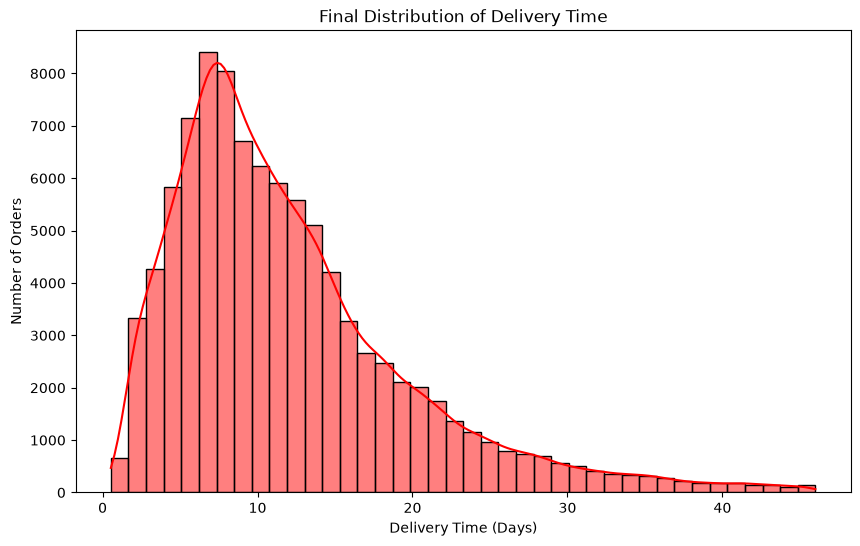

In [93]:
plt.figure(figsize=(10, 6))
sns.histplot(data=delivery_data, x='delivery_time_days', kde=True, bins=40, color="red")
plt.title('Final Distribution of Delivery Time')
plt.xlabel('Delivery Time (Days)')
plt.ylabel('Number of Orders')
plt.savefig('../images/final_delivery_time_distribution.png', bbox_inches='tight')
plt.show()

## Data Cleaning 

In [94]:
df = delivery_data.copy()

In [95]:
df.isnull().sum()

order_id                            0
purchase_dayofweek                  0
purchase_month                      0
purchase_hour                       0
purchase_is_weekend                 0
estimated_delivery_days             0
n_items                             0
n_sellers                           0
total_price                         0
total_freight                       0
avg_price                           0
product_weight_g                   16
product_length_cm                  16
product_height_cm                  16
product_width_cm                   16
payment_installments                0
payment_value                       0
payment_type                        0
customer_state                      0
seller_state                        0
product_category_name_english    1370
distance_km                       469
same_state                          0
delivery_time_days                  0
dtype: int64

In [96]:
# Removed rows where target is missing
df = df.dropna(subset=["delivery_time_days"])
print("missing target values:", df["delivery_time_days"].isnull().sum())
print("New shape:", df.shape)

missing target values: 0
New shape: (95497, 24)


In [97]:
# Filled numerical values with median because median is robust to outliers
numerical_columns = [
    "product_weight_g", "product_length_cm", "product_height_cm", 
    "product_width_cm", "payment_installments", "payment_value", 
    "distance_km"
]

for column in numerical_columns:
    df[column] = df[column].fillna(df[column].median())

In [98]:
df["product_category_name_english"].value_counts()

product_category_name_english
bed_bath_table               9059
health_beauty                8518
sports_leisure               7422
computers_accessories        6440
furniture_decor              6145
                             ... 
arts_and_craftmanship          22
cds_dvds_musicals              12
la_cuisine                     12
fashion_childrens_clothes       7
security_and_services           2
Name: count, Length: 71, dtype: int64

In [99]:
# As product category name was unknown so i filled missing values in product_category_name_english with Unknown
df["product_category_name_english"] = (df["product_category_name_english"].fillna("Unknown"))

In [100]:
df["payment_type"].value_counts()

payment_type
credit_card    73189
boleto         18994
voucher         1840
debit_card      1474
Name: count, dtype: int64

In [101]:
# Well, firstly i thought i should fill it with mode but then i thought it might be misleading so, i filled payment_type with Unknown
df["payment_type"] = df["payment_type"].fillna("Unknown")

In [102]:
# Dropped unnecessary column order_id
df.drop(columns='order_id', inplace=True)

In [103]:
print(df.isnull().sum())

purchase_dayofweek               0
purchase_month                   0
purchase_hour                    0
purchase_is_weekend              0
estimated_delivery_days          0
n_items                          0
n_sellers                        0
total_price                      0
total_freight                    0
avg_price                        0
product_weight_g                 0
product_length_cm                0
product_height_cm                0
product_width_cm                 0
payment_installments             0
payment_value                    0
payment_type                     0
customer_state                   0
seller_state                     0
product_category_name_english    0
distance_km                      0
same_state                       0
delivery_time_days               0
dtype: int64


## Checking for skewness 

In [104]:
numerical_columns = df.select_dtypes(include='number')
numerical_columns.skew()

purchase_dayofweek          0.169321
purchase_month              0.203271
purchase_hour              -0.599765
purchase_is_weekend         1.284689
estimated_delivery_days     0.864010
n_items                     7.562495
n_sellers                   9.823598
total_price                 9.970442
total_freight              12.444260
avg_price                   7.918026
product_weight_g            3.618034
product_length_cm           1.768922
product_height_cm           2.265347
product_width_cm            1.718013
payment_installments        1.608468
payment_value               9.447829
distance_km                 1.732331
same_state                  0.572096
delivery_time_days          1.399235
dtype: float64

* skewness > zero -> Right Skewed
* skewness = negative -> Left Skewed

**I will handle skewness in pipeline for n_items, n_sellers, total_price, total_freight, avg_price, product_weight_g, product_length_cm, product_height_cm, product_width_cm, payment_value, distance_km**

## Feature Encoding Strategy 

In [105]:
df.dtypes

purchase_dayofweek                 int64
purchase_month                     int64
purchase_hour                      int64
purchase_is_weekend                int64
estimated_delivery_days          float64
n_items                            int64
n_sellers                          int64
total_price                      float64
total_freight                    float64
avg_price                        float64
product_weight_g                 float64
product_length_cm                float64
product_height_cm                float64
product_width_cm                 float64
payment_installments             float64
payment_value                    float64
payment_type                         str
customer_state                       str
seller_state                         str
product_category_name_english        str
distance_km                      float64
same_state                         int64
delivery_time_days               float64
dtype: object

In [106]:
df['payment_type'].value_counts()

payment_type
credit_card    73189
boleto         18994
voucher         1840
debit_card      1474
Name: count, dtype: int64

In [107]:
# Contains 27 unique values 
len(df['customer_state'].value_counts())   

27

In [108]:
# Contains 22 unique values 
len(df['seller_state'].value_counts())   

22

In [109]:
# Contains 72 unique values ()
len(df['product_category_name_english'].value_counts())    

72

Since here categorical features are nominal and doesn't carry any meaningful order, label encoding could introduce a false relationship between categories. so, i will use one-hot encoding because it prevents the model from interpreting categories as having any numerical ranking

In [110]:
df.columns

Index(['purchase_dayofweek', 'purchase_month', 'purchase_hour',
       'purchase_is_weekend', 'estimated_delivery_days', 'n_items',
       'n_sellers', 'total_price', 'total_freight', 'avg_price',
       'product_weight_g', 'product_length_cm', 'product_height_cm',
       'product_width_cm', 'payment_installments', 'payment_value',
       'payment_type', 'customer_state', 'seller_state',
       'product_category_name_english', 'distance_km', 'same_state',
       'delivery_time_days'],
      dtype='str')

## Train Test Split 

In [111]:
skewed_features = [
    'n_items', 'n_sellers', 'total_price', 
    'total_freight', 'avg_price', 'product_weight_g', 
    'product_length_cm', 'product_height_cm',
    'product_width_cm', 'payment_value', 'distance_km'
]

calender_features = [
    'purchase_dayofweek', 'purchase_month', 
    'purchase_hour', 'purchase_is_weekend', 
    'same_state'
]

numeric_features = ['estimated_delivery_days', 'payment_installments',]

categorical_features = [
    'payment_type', 'customer_state', 
    'seller_state', 'product_category_name_english'
]

independent_features = skewed_features + calender_features + numeric_features + categorical_features

In [112]:
from sklearn.model_selection import train_test_split

X = df[independent_features]
y = df['delivery_time_days']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [113]:
print(X.shape)
print(y.shape)
print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

(95497, 22)
(95497,)
(76397, 22)
(76397,)
(19100, 22)
(19100,)


In [114]:
y_train.describe()

count    76397.000000
mean        12.034053
std          7.724711
min          0.533414
25%          6.706065
50%         10.148438
75%         15.336169
max         45.994248
Name: delivery_time_days, dtype: float64

In [115]:
y_test.describe()

count    19100.000000
mean        12.114267
std          7.771568
min          0.855313
25%          6.779010
50%         10.179091
75%         15.509650
max         45.999468
Name: delivery_time_days, dtype: float64

## Data Preprocessing using ColumnTransformer

In [116]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# For skewed features
skew_pipeline = Pipeline(steps=[
    ('log_transform', FunctionTransformer(np.log1p)),
    ('scale', StandardScaler())
])

# For numeric Features
scaling_pipeline = Pipeline(steps=[
    ('scale',StandardScaler())
])

# For categorical features
categorical_pipeline = Pipeline(steps=[
    ('encode', OneHotEncoder(handle_unknown="ignore"))
])

calendar_pipeline = Pipeline(steps=[
    ('passthrough', 'passthrough')  
])


preprocessor = ColumnTransformer(transformers=[
    ("skewness", skew_pipeline, skewed_features),
    ("scaler", scaling_pipeline, numeric_features),
    ("category", categorical_pipeline, categorical_features),
    ("calendar", calendar_pipeline, calender_features),
])

preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('skewness', ...), ('scaler', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``f

In [117]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

In [118]:
print("Preprocessed X_train shape:", X_train_processed.shape)
print("Preprocessed X_test shape:", X_test_processed.shape)

Preprocessed X_train shape: (76397, 143)
Preprocessed X_test shape: (19100, 143)


## Baseline Model Training 

In [119]:
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

In [120]:
models = {
    "Linear Regression": LinearRegression(),
    "KNN": KNeighborsRegressor(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),   
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.1, max_depth=6, random_state=42, n_jobs=-1), 
}

**Baseline Model Training**

In [121]:
results = []

for name, model in models.items():
    model.fit(X_train_processed, y_train)

    y_pred = model.predict(X_test_processed)

    results.append(
        {
            "Model": name,
            "MAE": mean_absolute_error(y_test, y_pred),
            "RMSE": root_mean_squared_error(y_test, y_pred),
            "R2 Score": r2_score(y_test, y_pred),
        }
    )

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(by="MAE").reset_index(drop=True)

results_df.round(3)

,Model,MAE,RMSE,R2 Score
0,XGBoost,4.225,5.934,0.417
1,Random Forest,4.255,5.967,0.410
2,Linear Regression,4.594,6.398,0.322
3,KNN,4.876,6.772,0.241
4,Decision Tree,5.863,8.408,-0.170


**Well, i evaluated five baseline regression models and XGboost (MAE: 4.225 days, RMSE: 5.934 days, and R²: 0.417) and random forest (MAE: 4.255 days, RMSE: 5.967 days, and R²: 0.410) performed best. i selected xgboost and random forest as the baseline champion and will now optimize both hyperparameters to improve prediction performance.**

## Hyperparameter Optimization 

**Tuned random forest model**

In [123]:
from sklearn.model_selection import RandomizedSearchCV

rf_pipeline = Pipeline([
    ('preprocessor', preprocessor), 
    ('regressor', RandomForestRegressor(random_state=42))
])

rf_params = {
    'regressor__n_estimators': [50, 100, 150, 200],
    'regressor__max_depth': [None, 5, 10, 15],
    'regressor__min_samples_split': [2, 5, 8, 10],
    'regressor__min_samples_leaf': [1, 2, 4, 6]
}

tuned_rf = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=rf_params,
    n_iter=5,
    cv=3,
    scoring='neg_mean_absolute_error',
    random_state=42,
    n_jobs=-1,     
    verbose=3
)

tuned_rf.fit(X_train, y_train)

Fitting 3 folds for each of 5 candidates, totalling 15 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'regressor__max_depth': [None, 5, ...], 'regressor__min_samples_leaf': [1, 2, ...], 'regressor__min_samples_split': [2, 5, ...], 'regressor__n_estimators': [50, 100, ...]}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",5
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_mean_absolute_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",3
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a bes

In [124]:
print(tuned_rf.best_params_)
print("best cv mae of tuned random forest:", -tuned_rf.best_score_)

{'regressor__n_estimators': 50, 'regressor__min_samples_split': 5, 'regressor__min_samples_leaf': 4, 'regressor__max_depth': 15}
best cv mae of tuned random forest: 4.274424430031245


**Tuned xgboost model**

In [125]:
xgb_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', XGBRegressor(random_state=42))
])

xgb_params = {
    'regressor__n_estimators'  : [100, 150, 200, 300, 400],
    'regressor__max_depth'     : [3, 5, 7, 9, 12],
    'regressor__learning_rate' : [0.01, 0.05, 0.1, 0.2, 0.5],
    'regressor__subsample'     : [0.7, 0.85, 1.0],
}

tuned_xgb = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=xgb_params,
    n_iter=20,
    cv=5,
    scoring='neg_mean_absolute_error',
    random_state=42,
    n_jobs=1,
    verbose=1
)

tuned_xgb.fit(X_train, y_train)

Fitting 5 folds for each of 20 candidates, totalling 100 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'regressor__learning_rate': [0.01, 0.05, ...], 'regressor__max_depth': [3, 5, ...], 'regressor__n_estimators': [100, 150, ...], 'regressor__subsample': [0.7, 0.85, ...]}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",20
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_mean_absolute_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a bes

In [126]:
print(tuned_xgb.best_params_)
print("best cv mae of tuned xgb:", -tuned_xgb.best_score_)

{'regressor__subsample': 0.7, 'regressor__n_estimators': 200, 'regressor__max_depth': 9, 'regressor__learning_rate': 0.05}
best cv mae of tuned xgb: 4.173672087344711


## Final model evaluation 

In [127]:
def evaluate(name, tuned_pipeline):
    y_pred = tuned_pipeline.predict(X_test)

    return {
        "Model": name,
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": root_mean_squared_error(y_test, y_pred),
        "R2 Score": r2_score(y_test, y_pred),
    }

In [128]:
tuned_results = [
    evaluate("Tuned Random Forest", tuned_rf.best_estimator_),
    evaluate("Tuned XGBoost", tuned_xgb.best_estimator_),
]

In [129]:
tuned_results_df = pd.DataFrame(tuned_results)
tuned_results_df = tuned_results_df.sort_values(by="MAE", ascending=True).reset_index(drop=True)
tuned_results_df.round(3)

,Model,MAE,RMSE,R2 Score
0,Tuned XGBoost,4.156,5.869,0.430
1,Tuned Random Forest,4.254,5.978,0.408


## After Log Transformation

In [130]:
from sklearn.compose import TransformedTargetRegressor

xgb_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', XGBRegressor(random_state=42))
])

log_xgb_pipeline = TransformedTargetRegressor(
    regressor=xgb_pipeline,
    func=np.log1p,
    inverse_func=np.expm1
)

xgb_params = {
    'regressor__regressor__learning_rate' : [0.01, 0.05, 0.1, 0.2, 0.5],
    'regressor__regressor__subsample'     : [0.7, 0.85, 1.0],
}

log_tuned_xgb = RandomizedSearchCV(
    estimator=log_xgb_pipeline,
    param_distributions=xgb_params,
    n_iter=10,
    cv=5,
    scoring='neg_mean_absolute_error',
    random_state=42,
    n_jobs=1,
    verbose=1
)

log_tuned_xgb.fit(X_train, y_train)


Fitting 5 folds for each of 10 candidates, totalling 50 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","TransformedTa...None, ...))]))"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'regressor__regressor__learning_rate': [0.01, 0.05, ...], 'regressor__regressor__subsample': [0.7, 0.85, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_mean_absolute_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturn

In [131]:
print(log_tuned_xgb.best_params_)
print("best cv mae of log tuned xgb:", -log_tuned_xgb.best_score_)

{'regressor__regressor__subsample': 1.0, 'regressor__regressor__learning_rate': 0.2}
best cv mae of log tuned xgb: 4.0662353120295


In [132]:
evaluate("Log Transformed Tuned XGBoost", log_tuned_xgb.best_estimator_)

{'Model': 'Log Transformed Tuned XGBoost',
 'MAE': 4.073901327085616,
 'RMSE': 6.031648575126648,
 'R2 Score': 0.3976103086770222}

In [133]:
comparison = [
    evaluate("Tuned XGBoost", tuned_xgb.best_estimator_),
    evaluate("Log Transformed Tuned XGB", log_tuned_xgb.best_estimator_)
]

comparison_df = pd.DataFrame(comparison)
comparison_df.round(3)


,Model,MAE,RMSE,R2 Score
0,Tuned XGBoost,4.156,5.869,0.430
1,Log Transformed Tuned XGB,4.074,6.032,0.398


## Saved best model 

In [134]:
import joblib
joblib.dump(tuned_xgb.best_estimator_, "../model/delivero_model.pkl")

['../model/delivero_model.pkl']